## Importing Libraries

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from kneed import KneeLocator
from sklearn.metrics import silhouette_score
from sklearn.cluster import AgglomerativeClustering

## loading data

In [2]:
df=pd.read_csv("smartcart_customers.csv")
df.head(5)
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

## Filing missing vals

In [3]:
df['Income'] = pd.to_numeric(df['Income'], errors='coerce')
median_income = df['Income'].median()
df['Income'] = df['Income'].fillna(median_income)

## Feature Engineering

In [4]:
# age
df["age"]=2026-df["Year_Birth"]

In [5]:
# Total Spending
df["Total_spending"]=df["MntWines"] + df["MntMeatProducts"] + df["MntFruits"] + df["MntFishProducts"] + df["MntSweetProducts"] + df["MntGoldProds"]

In [6]:
# Total children
df["Total_children"]=df["Kidhome"] + df["Teenhome"]

In [7]:
# Customer joining date
df["Dt_Customer"]=pd.to_datetime(df["Dt_Customer"],dayfirst=True)
ref_date=df["Dt_Customer"].max()
df["customer_tenure"]=(ref_date-df["Dt_Customer"]).dt.days

In [8]:
# Education_level

df["Education"]=df["Education"].replace({
    "Basic" : "UnderGraduate" , "2n Cycle" : "UnderGraduate",
    "Graduation" : "Graduate",
    "PhD" : "PostGraduate" , "Master" : "PostGraduate"
})

In [9]:
# Marital status

df["Living_with"]=df["Marital_Status"].replace({
    "Married" : "Partner" , "Together" : "Partner",
    "Single" : "Alone" , "Divorced" : "Alone" , "YOLO" : "Alone" , "Absurd" : "Alone" , "Widow" : "Alone"
})


## Drop Columns

In [10]:
cols=["ID","Year_Birth","Marital_Status","Kidhome","Teenhome","Dt_Customer","MntWines","MntFruits","MntMeatProducts","MntFishProducts","MntSweetProducts","MntGoldProds"]
df_cleaned=df.drop(columns=cols)

In [11]:
df_cleaned.columns

Index(['Education', 'Income', 'Recency', 'NumDealsPurchases',
       'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases',
       'NumWebVisitsMonth', 'Complain', 'Response', 'age', 'Total_spending',
       'Total_children', 'customer_tenure', 'Living_with'],
      dtype='object')

## Removing Outilers

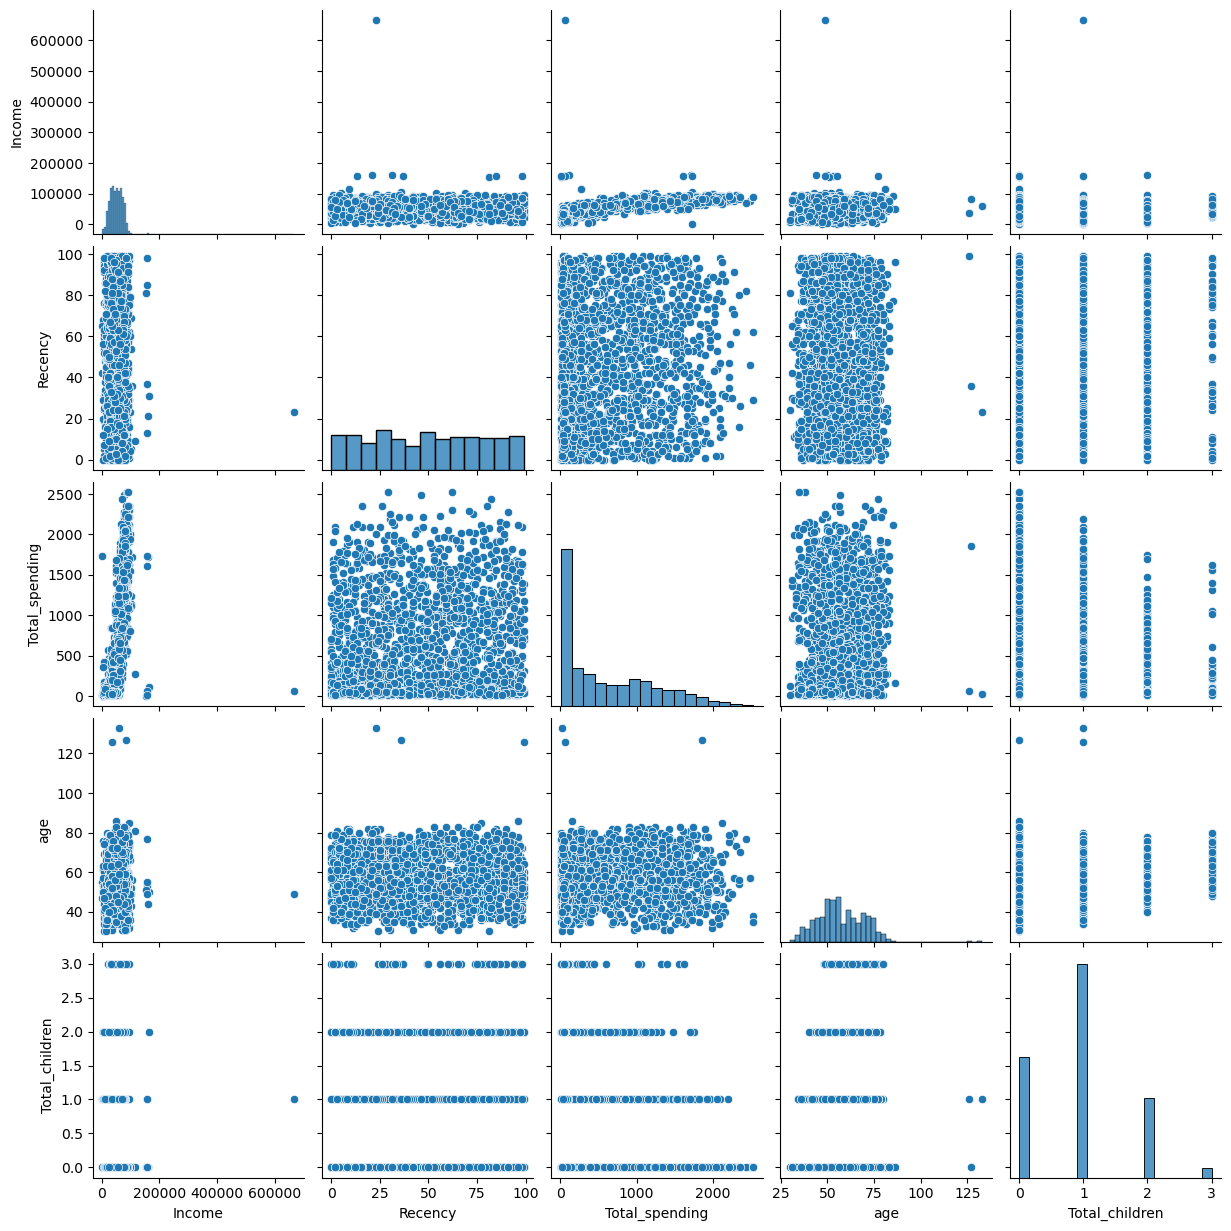

In [12]:
cols=["Income","Recency","Total_spending","age","Total_children"]
sns.pairplot(df_cleaned[cols])

In [13]:
print("Before removing outliers size:",len(df_cleaned))
df_cleaned=df_cleaned[(df_cleaned["age"] < 90)]
df_cleaned=df_cleaned[(df_cleaned["Income"] < 600000)]
print("After removing outliers size:",len(df_cleaned))

Before removing outliers size: 2240
After removing outliers size: 2236


## Heatmap

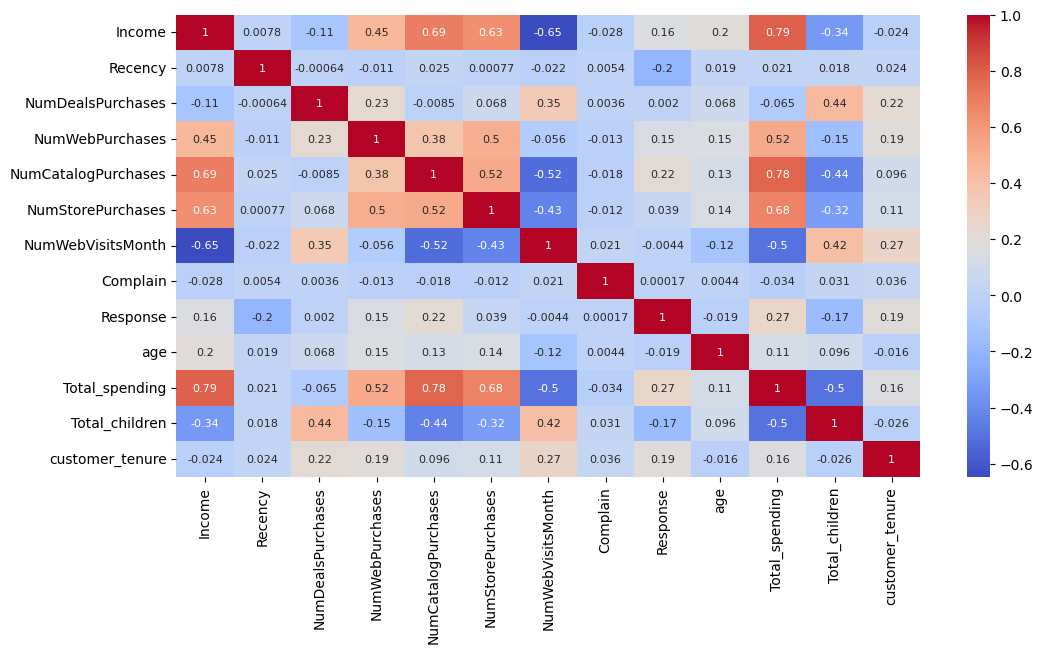

In [14]:
corr=df_cleaned.corr(numeric_only=True)
plt.figure(figsize=(12,6))
sns.heatmap(
    corr,
    annot=True,
    annot_kws={"size":8},
    cmap="coolwarm"
)
plt.savefig("Heatmap")

## Encoding

In [15]:
ohe=OneHotEncoder()
cat_cols=["Education","Living_with"]
enc_cols=ohe.fit_transform(df_cleaned[cat_cols])

In [16]:
enc_cols=pd.DataFrame(enc_cols.toarray(),columns=ohe.get_feature_names_out(cat_cols), index=df_cleaned.index)

In [17]:
df_encoded=pd.concat([df_cleaned.drop(columns=cat_cols),enc_cols],axis=1)

In [18]:
df_encoded.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,age,Total_spending,Total_children,customer_tenure,Education_Graduate,Education_PostGraduate,Education_UnderGraduate,Living_with_Alone,Living_with_Partner
0,58138.0,58,3,8,10,4,7,0,1,69,1617,0,663,1.0,0.0,0.0,1.0,0.0
1,46344.0,38,2,1,1,2,5,0,0,72,27,2,113,1.0,0.0,0.0,1.0,0.0
2,71613.0,26,1,8,2,10,4,0,0,61,776,0,312,1.0,0.0,0.0,0.0,1.0
3,26646.0,26,2,2,0,4,6,0,0,42,53,1,139,1.0,0.0,0.0,0.0,1.0
4,58293.0,94,5,5,3,6,5,0,0,45,422,1,161,0.0,1.0,0.0,0.0,1.0


## Scaling

In [19]:
scaler=StandardScaler()
X=df_encoded
X_scaled=scaler.fit_transform(X)

## Visualization

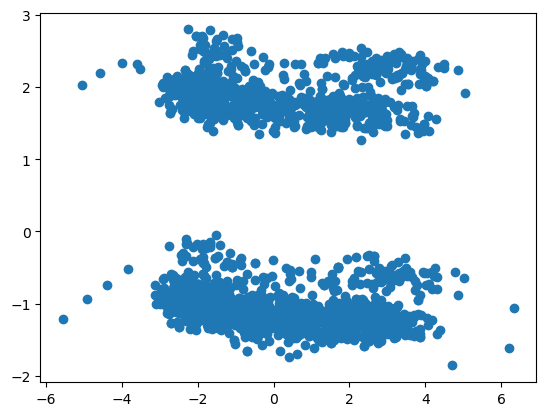

In [20]:
# 2D
pca=PCA(n_components=2)
X_pca=pca.fit_transform(X_scaled)
plt.scatter(X_pca[:,0],X_pca[:,1])

In [21]:
pca.explained_variance_ratio_

array([0.23163158, 0.11385454])

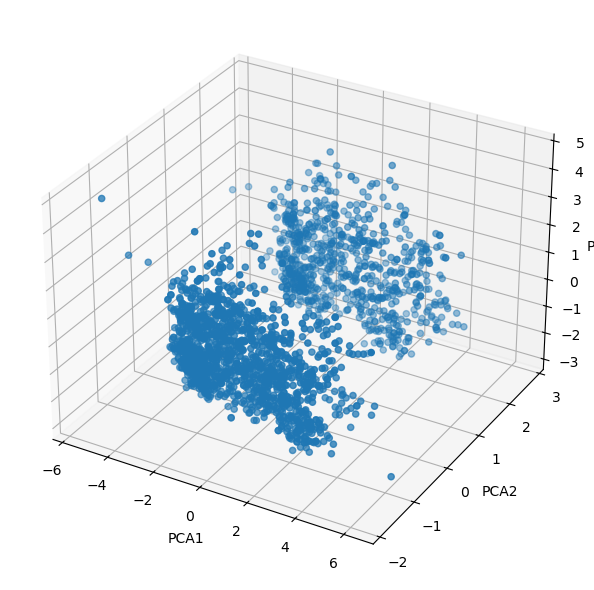

In [22]:
# 3D
fig=plt.figure(figsize=(8,6))
pca=PCA(n_components=3)
X_pca=pca.fit_transform(X_scaled)
ax=fig.add_subplot(111,projection="3d")
ax.scatter(X_pca[:,0],X_pca[:,1],X_pca[:,2])
ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")
plt.tight_layout()

## 1.Elbow Method

In [23]:
wcss=[]
for k in range(1,11):
    kmeans=KMeans(n_clusters=k,random_state=42)
    kmeans.fit_predict(X_pca)
    wcss.append(kmeans.inertia_)
    
    

In [24]:
knee=KneeLocator(range(1,11),wcss,curve="convex",direction="decreasing")
optimal_k=knee.elbow
print("Best k value :", optimal_k)

Best k value : 4


Text(0.5, 1.0, 'K value using elbow method')

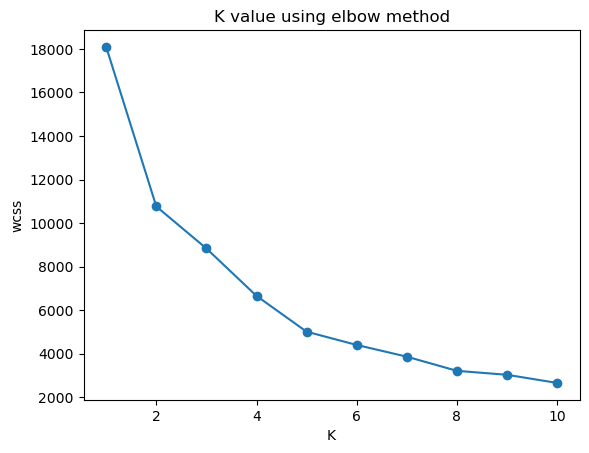

In [25]:
plt.plot(range(1,11),wcss,marker="o")
plt.xlabel("K")
plt.ylabel("wcss")
plt.title("K value using elbow method")

## 2. Silhouette score

In [26]:
scores=[]
for k in range(2,11):
    kmeans=KMeans(n_clusters=k,random_state=42)
    labels=kmeans.fit_predict(X_pca)
    score=silhouette_score(X_pca,labels)
    scores.append(score)

Text(0.5, 1.0, 'K values using silhouette score')

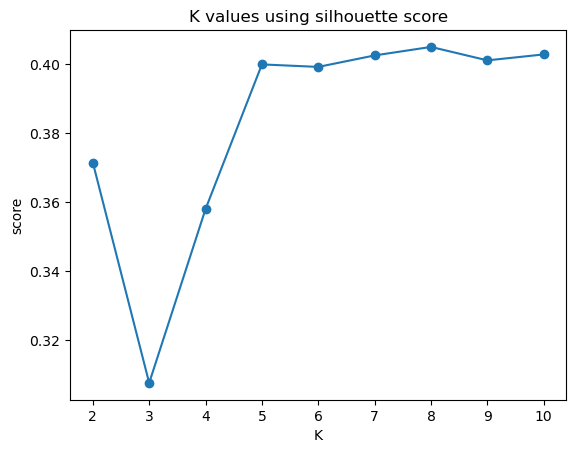

In [27]:
plt.plot(range(2,11),scores,marker="o")
plt.xlabel("K")
plt.ylabel("score")
plt.title("K values using silhouette score")

Text(0.5, 1.0, 'elbow method and silhouette_score')

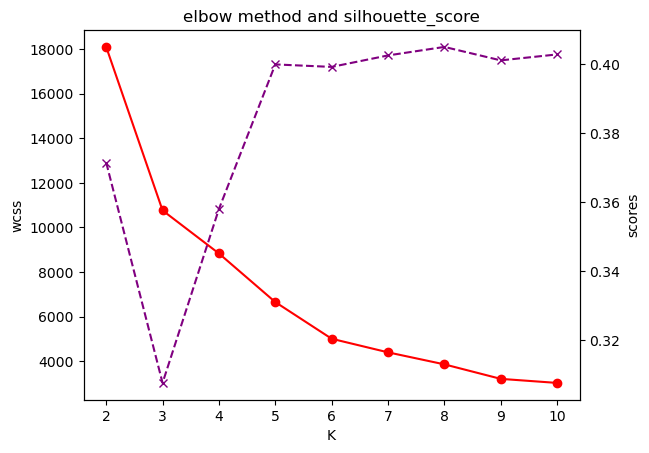

In [28]:
# Combining both methods graph

k_range=range(2,11)
fig ,ax1=plt.subplots()
ax1.plot(k_range,wcss[:len(k_range)],marker="o",color="red")
ax1.set_xlabel("K")
ax1.set_ylabel("wcss")
ax2=ax1.twinx()
ax2.plot(k_range,scores[:len(k_range)],marker="x",color="purple",linestyle="--")
ax2.set_ylabel("scores")
plt.title("elbow method and silhouette_score")

## Clustering

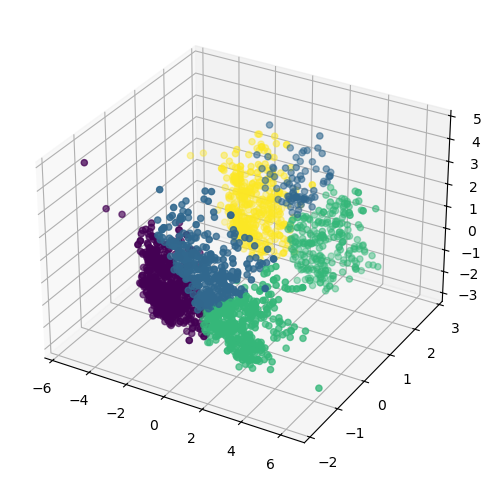

In [29]:
# kmeans clustering
kmeans=KMeans(n_clusters=4,random_state=42)
kmeans_labels=kmeans.fit_predict(X_pca)
fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(111,projection="3d")
ax.scatter(X_pca[:,0],X_pca[:,1],X_pca[:,2],c=kmeans_labels)

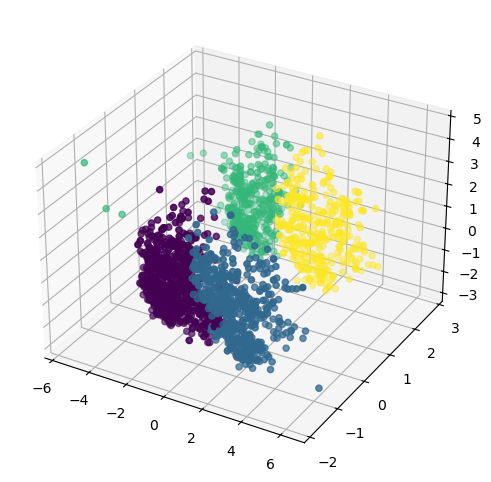

In [30]:
# Agglomerative Clustering
agg_clus=AgglomerativeClustering(n_clusters=4)
agg_labels=agg_clus.fit_predict(X_pca)
fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(111,projection="3d")
ax.scatter(X_pca[:,0],X_pca[:,1],X_pca[:,2],c=agg_labels)

In [48]:
X["cluster"]=agg_labels
pal=["red","blue","green","orange"]

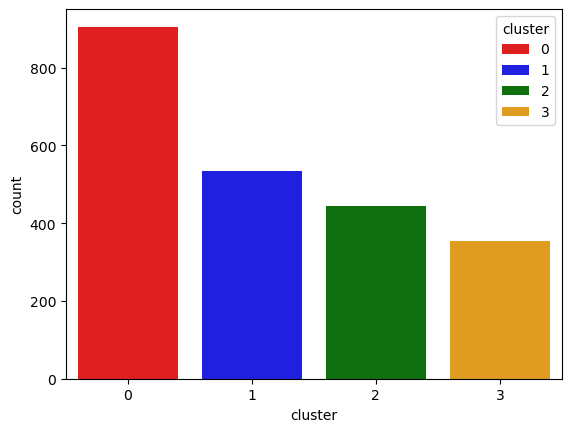

In [49]:
cluster=sns.countplot(x=X["cluster"],palette=pal,hue=X["cluster"])

<Axes: xlabel='Total_spending', ylabel='Income'>

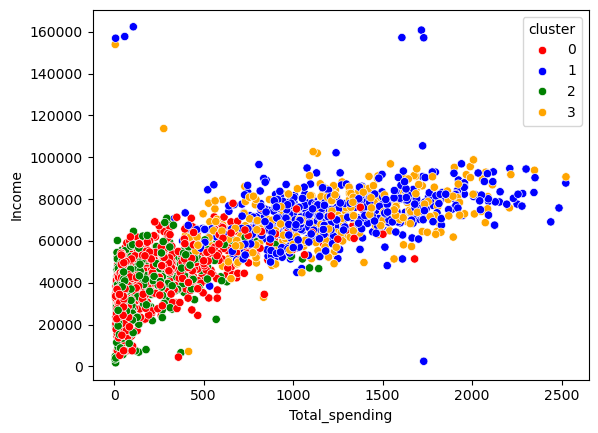

In [50]:
# Income v/s spending rel


sns.scatterplot(x=df_cleaned["Total_spending"],y=df_cleaned["Income"],hue=X["cluster"],palette=pal)

In [52]:
cluster_summary=X.groupby("cluster").mean()

In [55]:
cluster_summary

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,age,Total_spending,Total_children,customer_tenure,Education_Graduate,Education_PostGraduate,Education_UnderGraduate,Living_with_Alone,Living_with_Partner
cluster,,,,,,,,,,,,,,,,,,
0,39680.580110,48.914917,2.594475,3.153591,0.969061,4.143646,6.307182,0.011050,0.076243,55.669613,221.955801,1.243094,342.939227,0.514917,0.338122,0.146961,0.000000,1.000000
1,72808.445693,49.202247,1.958801,5.687266,5.498127,8.659176,3.580524,0.005618,0.166667,59.492509,1236.588015,0.511236,369.720974,0.471910,0.455056,0.073034,0.000000,1.000000
2,36960.143018,48.319820,2.594595,2.713964,0.837838,3.623874,6.659910,0.011261,0.141892,55.691441,165.702703,1.272523,338.781532,0.488739,0.378378,0.132883,0.993243,0.006757
3,70722.681303,50.504249,1.855524,5.790368,5.014164,8.430595,3.728045,0.005666,0.320113,58.932011,1190.385269,0.461756,376.280453,0.541076,0.390935,0.067989,1.000000,0.000000
